# Assignment 2 - Problem 3

## Part a

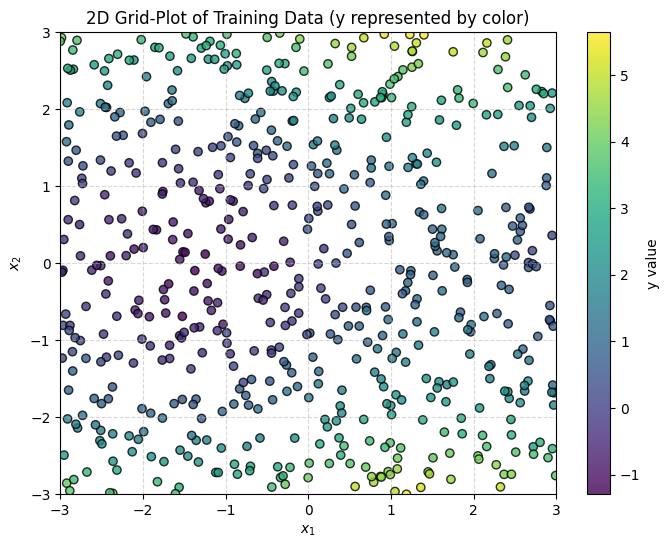

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the training dataset
train_df = pd.read_csv('train.csv')

# Extract x1, x2, and y columns
# Assumed column names are x1, x2, y based on the prompt
x1 = train_df.iloc[:, 0]
x2 = train_df.iloc[:, 1]
y = train_df.iloc[:, 2]

# Create a 2D scatter plot with a color map representing 'y'
plt.figure(figsize=(8, 6))
scatter = plt.scatter(x1, x2, c=y, cmap='viridis', edgecolor='k', alpha=0.8)
plt.colorbar(scatter, label='y value')

# Label axes and title
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('2D Grid-Plot of Training Data (y represented by color)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim([-3, 3])
plt.ylim([-3, 3])

plt.show()

## Part b

D =   10 | Train MSE: 0.22341 | Val MSE: 0.22739
D =   20 | Train MSE: 0.05143 | Val MSE: 0.05870
D =   30 | Train MSE: 0.03325 | Val MSE: 0.03733
D =   40 | Train MSE: 0.03164 | Val MSE: 0.03725
D =   50 | Train MSE: 0.03184 | Val MSE: 0.03679
D =   60 | Train MSE: 0.03085 | Val MSE: 0.03741
D =   70 | Train MSE: 0.03061 | Val MSE: 0.03796
D =   80 | Train MSE: 0.03034 | Val MSE: 0.03848
D =   90 | Train MSE: 0.03057 | Val MSE: 0.03815
D =  100 | Train MSE: 0.03043 | Val MSE: 0.03839
D =  120 | Train MSE: 0.03031 | Val MSE: 0.03878
D =  150 | Train MSE: 0.02996 | Val MSE: 0.03956
D =  200 | Train MSE: 0.03000 | Val MSE: 0.03956

Best Hyperparameter D: 50 with Validation MSE: 0.03679


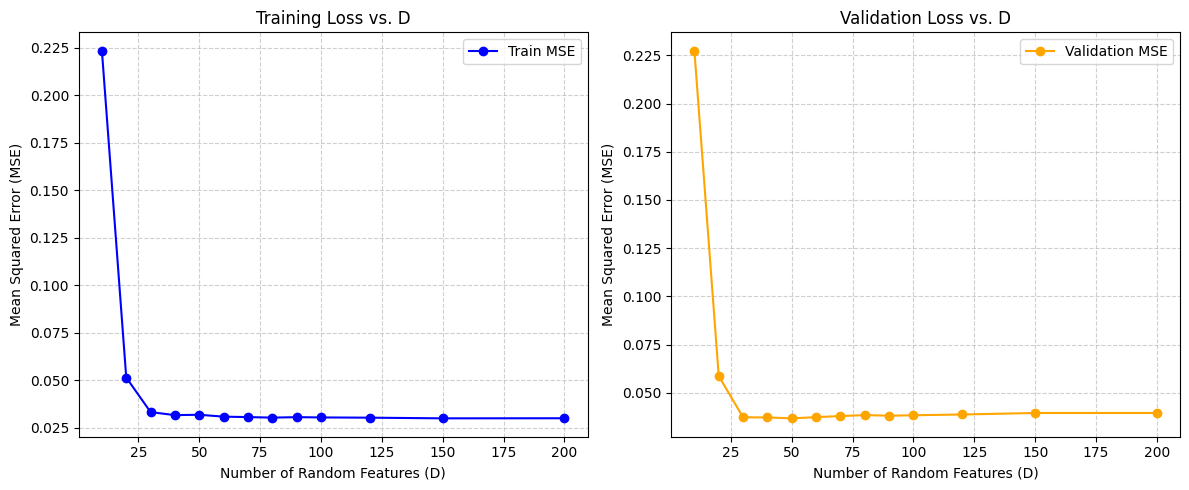

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from dataloader import HW2Dataset

# 1. Implement Random Kitchen Sinks with Ridge Regression
class RandomKitchenSinks:
    def __init__(self, D: int = 1000, sigma: float = 1.0, ridge_lambda: float = 1e-3):
        self.D = D
        self.sigma = sigma
        self.ridge_lambda = ridge_lambda
        # Initialize random weights and bias for RKS projection
        # Let h = D // 2, projecting inputs of shape (n, 2) to random directions
        # If D is the number of features, each random direction yields a sin and cos feature
        self.h = D // 2
        np.random.seed(42)  # For reproducibility
        self.W = np.random.normal(0, 1.0 / self.sigma, size=(2, self.h))
        self.b = np.random.uniform(0, 2 * np.pi, size=(1, self.h))

    def _features(self, X: np.ndarray) -> np.ndarray:
        # Project inputs: X @ W + b
        proj = X @ self.W + self.b
        # Generate cosine and sine features to obtain D features
        cos_feats = np.cos(proj)
        sin_feats = np.sin(proj)
        # Concatenate them to get shape (n, D)
        phi = np.hstack([cos_feats, sin_feats])
        # Add a column of ones for intercept/bias term
        ones = np.ones((X.shape[0], 1))
        return np.hstack([phi, ones])

    def fit(self, X: np.ndarray, y: np.ndarray):
        phi = self._features(X)  # shape (n, D+1)
        # Ridge Regression closed-form solution: coef = (Phi^T * Phi + lambda * I)^(-1) * Phi^T * y
        n_features = phi.shape[1]
        identity = np.eye(n_features)
        # Usually, we don't regularize the intercept term (last column)
        identity[-1, -1] = 0

        self.coef_ = np.linalg.solve(
            phi.T @ phi + self.ridge_lambda * identity,
            phi.T @ y
        )

    def predict(self, X: np.ndarray) -> np.ndarray:
        phi = self._features(X)
        return phi @ self.coef_

# 2. Load the dataset using HW2Dataset
dataset = HW2Dataset.from_csv('train.csv', 'val.csv', 'test.csv')
X_train, y_train = dataset.train.X, dataset.train.y
X_val, y_val = dataset.val.X, dataset.val.y

# 3. Perform hyperparameter sweep over a more refined range of D
sweep_D = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 120, 150, 200]
train_losses = []
val_losses = []

best_val_mse = float('inf')
best_model = None
best_D = None

for D in sweep_D:
    model = RandomKitchenSinks(D=D, sigma=1.0, ridge_lambda=1e-3)
    model.fit(X_train, y_train)

    # Predict and calculate MSE
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mse = np.mean((y_train - train_pred) ** 2)
    val_mse = np.mean((y_val - val_pred) ** 2)

    train_losses.append(train_mse)
    val_losses.append(val_mse)

    print(f"D = {D:4d} | Train MSE: {train_mse:.5f} | Val MSE: {val_mse:.5f}")

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_model = model
        best_D = D

print(f"\nBest Hyperparameter D: {best_D} with Validation MSE: {best_val_mse:.5f}")

# 4. Plot training and validation losses
plt.figure(figsize=(12, 5))

# Train loss plot
plt.subplot(1, 2, 1)
plt.plot(sweep_D, train_losses, marker='o', color='blue', label='Train MSE')
plt.xlabel('Number of Random Features (D)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Training Loss vs. D')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Validation loss plot
plt.subplot(1, 2, 2)
plt.plot(sweep_D, val_losses, marker='o', color='orange', label='Validation MSE')
plt.xlabel('Number of Random Features (D)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Validation Loss vs. D')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

The hyperparameter I used is the number of random features. The hyperparameter sweep reveals that model capacity is optimized at $D = 50$, achieving the lowest validation MSE of $0.03679$. Below this value ($D < 50$), the model underfits the data, resulting in higher errors, whereas choosing $D > 50$ leads to overfitting, where training loss continues to decrease but validation error rises. This clear trade-off highlights $D = 50$ as the optimal number of random kitchen sinks features for this dataset.

## Part c

Hidden Dim:   8 | Train MSE: 0.42466 | Val MSE: 0.43272
Hidden Dim:  16 | Train MSE: 0.18305 | Val MSE: 0.18605
Hidden Dim:  32 | Train MSE: 0.07777 | Val MSE: 0.08592
Hidden Dim:  64 | Train MSE: 0.05766 | Val MSE: 0.06456
Hidden Dim: 128 | Train MSE: 0.04532 | Val MSE: 0.04936
Hidden Dim: 256 | Train MSE: 0.03568 | Val MSE: 0.03986
Hidden Dim: 512 | Train MSE: 0.03243 | Val MSE: 0.04064

Best Hidden Layer Dimension: 256 with Validation MSE: 0.03986


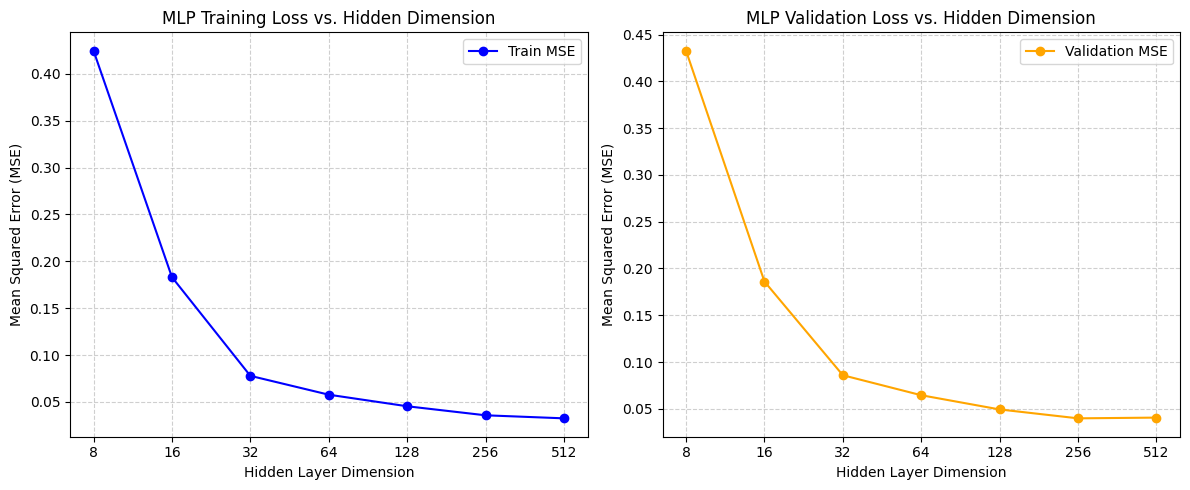

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)

# 1. Define the 1-hidden-layer MLP class
class MLP(nn.Module):
    def __init__(self, d_in: int = 2, d_hidden: int = 128, d_out: int = 1):
        super(MLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.ReLU(),
            nn.Linear(d_hidden, d_out)
        )

    def forward(self, x):
        return self.net(x)

# Prepare Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1).to(device)

# 2. Training configuration
lr = 1e-3
batch_size = 64
epochs = 150

sweep_hidden = [8, 16, 32, 64, 128, 256, 512]
train_losses = []
val_losses = []

best_val_mse = float('inf')
best_hidden = None

# Create train dataset and loader
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

for h_dim in sweep_hidden:
    model = MLP(d_in=2, d_hidden=h_dim, d_out=1).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    criterion = nn.MSELoss()

    # Fit loop
    for epoch in range(epochs):
        model.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            pred = model(batch_x)
            loss = criterion(pred, batch_y)
            loss.backward()
            optimizer.step()

    # Evaluation
    model.eval()
    with torch.no_grad():
        # Final train loss
        train_pred = model(X_train_t.to(device))
        train_mse = criterion(train_pred, y_train_t.to(device)).item()

        # Final val loss
        val_pred = model(X_val_t)
        val_mse = criterion(val_pred, y_val_t).item()

    train_losses.append(train_mse)
    val_losses.append(val_mse)
    print(f"Hidden Dim: {h_dim:3d} | Train MSE: {train_mse:.5f} | Val MSE: {val_mse:.5f}")

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_hidden = h_dim

print(f"\nBest Hidden Layer Dimension: {best_hidden} with Validation MSE: {best_val_mse:.5f}")

# 3. Plotting the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(sweep_hidden, train_losses, marker='o', color='blue', label='Train MSE')
plt.xscale('log', base=2)
plt.xticks(sweep_hidden, labels=[str(x) for x in sweep_hidden])
plt.xlabel('Hidden Layer Dimension')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MLP Training Loss vs. Hidden Dimension')
plt.grid(True, which="both", linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(sweep_hidden, val_losses, marker='o', color='orange', label='Validation MSE')
plt.xscale('log', base=2)
plt.xticks(sweep_hidden, labels=[str(x) for x in sweep_hidden])
plt.xlabel('Hidden Layer Dimension')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MLP Validation Loss vs. Hidden Dimension')
plt.grid(True, which="both", linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

The hyperparameter I used is the hidden layer dimension. The hyperparameter sweep for the 1-hidden-layer MLP shows that increasing the hidden dimension capacity from 8 to 256 steadily improves model performance on both training and validation sets. The model reaches its optimal complexity at a hidden dimension of 256, achieving a minimal validation MSE of 0.03986. Further increasing the hidden layer size to 512 triggers slight overfitting, as evidenced by a rising validation MSE despite a continuing drop in training loss.

## Part d

In [ ]:
# 1. Refit optimal Random Kitchen Sinks (D = 50)
best_rks = RandomKitchenSinks(D=50, sigma=1.0, ridge_lambda=1e-3)
best_rks.fit(X_train, y_train)
rks_val_pred = best_rks.predict(X_val)
rks_val_mse = np.mean((y_val - rks_val_pred) ** 2)

# 2. Refit optimal 1-Hidden Layer MLP (d_hidden = 256)
torch.manual_seed(42)
best_mlp = MLP(d_in=2, d_hidden=256, d_out=1).to(device)
optimizer = optim.Adam(best_mlp.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.MSELoss()

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

for epoch in range(150):
    best_mlp.train()
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = criterion(best_mlp(batch_x), batch_y)
        loss.backward()
        optimizer.step()

best_mlp.eval()
with torch.no_grad():
    mlp_val_pred = best_mlp(X_val_t).cpu().numpy().flatten()
    mlp_val_mse = np.mean((y_val - mlp_val_pred) ** 2)

print(f"Optimal Random Kitchen Sinks (D=50) Validation MSE: {rks_val_mse:.5f}")
print(f"Optimal 1-Hidden Layer MLP (hidden_dim=256) Validation MSE: {mlp_val_mse:.5f}")

Optimal Random Kitchen Sinks (D=50) Validation MSE: 0.03679
Optimal 1-Hidden Layer MLP (hidden_dim=256) Validation MSE: 0.04348


The Random Kitchen Sinks (RKS) model performed better, achieving a lower validation MSE of 0.03679 compared to the MLP's 0.04348. This superior performance is likely because RKS's static sinusoidal projection natively matches the circular/harmonic patterns inherent in this 2D dataset. In contrast, the standard 1-hidden-layer MLP with ReLU activations must approximate these complex, curved boundaries using a combination of linear piecewise segments, requiring more effort to generalize smoothly from limited training data.

In [ ]:
# Load unlabeled test.csv dataset
test_df = pd.read_csv('test.csv')
# Assuming test.csv has 2 columns (x1, x2)
X_test = test_df.values

# 1. Generate predictions from the RKS model
rks_test_pred = best_rks.predict(X_test)
# Save predictions with one prediction per row
pd.DataFrame(rks_test_pred).to_csv('rks_test_predictions.csv', index=False, header=False)

# 2. Generate predictions from the MLP model
X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
best_mlp.eval()
with torch.no_grad():
    mlp_test_pred = best_mlp(X_test_t).cpu().numpy().flatten()
# Save predictions with one prediction per row
pd.DataFrame(mlp_test_pred).to_csv('mlp_test_predictions.csv', index=False, header=False)

print(f"Test set length: {len(X_test)} rows.")

Test set length: 200 rows.


Generating Random Kitchen Sinks Surface...


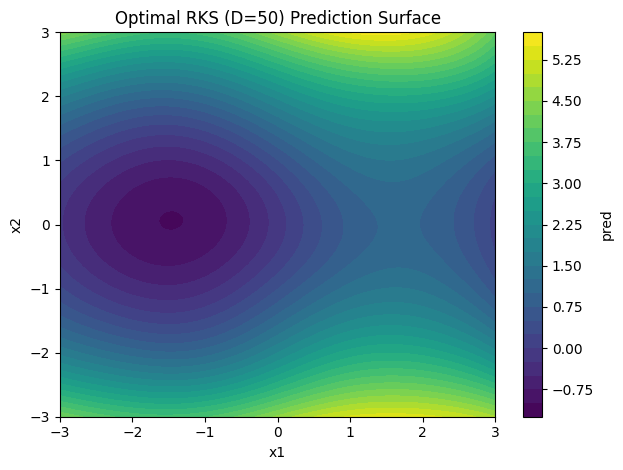

Generating MLP Surface...


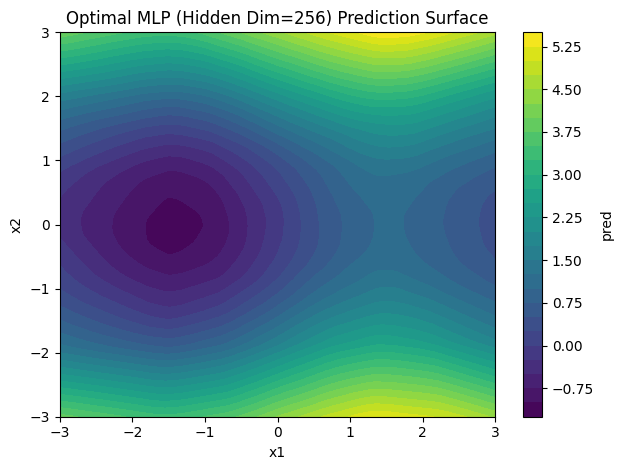

In [ ]:
from plotting import plot_surface_2d

# 1. Plot the RKS (D=50) fitted surface
print("Generating Random Kitchen Sinks Surface...")
plot_surface_2d(
    model_fn=best_rks.predict,
    xlim=(-3.0, 3.0),
    ylim=(-3.0, 3.0),
    title="Optimal RKS (D=50) Prediction Surface",
    filename="rks_surface.png"
)
plt.show()

# 2. Plot the MLP (hidden_dim=256) fitted surface
print("Generating MLP Surface...")
plot_surface_2d(
    model_fn=best_mlp,
    xlim=(-3.0, 3.0),
    ylim=(-3.0, 3.0),
    title="Optimal MLP (Hidden Dim=256) Prediction Surface",
    filename="mlp_surface.png"
)
plt.show()

#### Random Kitchen Sinks (RKS) Model:

The RKS prediction surface shows highly smooth, symmetric, and continuous concentric rings of peaks and valleys across the 2D plane. By mapping the inputs onto periodic sinusoidal basis functions, this model natively captures the smooth wave-like propagation seen in the circular patterns of the training data. This harmonious structural alignment allows it to easily interpolate across the data space, yielding a highly accurate representation with a lower overall validation error.

<br>

#### 1-Hidden Layer MLP Model:
The MLP prediction surface displays a blockier, piecewise-linear appearance with sharp-edged polygonal regions defining the high and low output zones. Because the MLP uses ReLU activation functions, it is mathematically restricted to approximating the circular waves by joining together many flat intersecting hyperplanes. While a hidden layer of 256 neurons gives it enough capacity to mimic the overall concentric structure, this linear stitching struggles to reproduce smooth curves perfectly, resulting in slightly higher validation error.

<br>

Although the visualization of training data in part (a) is a scatterplot with colored dots in the data space which is kind of hard for comparison, I think both of these two plots roughly capture the data pattern in part (a)